# AAI 540 Product QA Data Lake Feature Store and Data Splits

This notebook builds a reproducible AWS data workflow for the **Retrieval Augmented Product Question Answering** project. It:

1. downloads the official English ePQA files and saves the unchanged bytes plus checksums in an Amazon S3 raw zone;
2. validates, normalizes, and stores a curated Parquet dataset in S3;
3. catalogs raw, curated, feature, and split datasets in AWS Glue and queries them with Amazon Athena;
4. performs exploratory data analysis in SageMaker AI JupyterLab;
5. engineers leakage-safe scalar ranking features and ingests them into SageMaker Feature Store's offline store;
6. makes product-grouped training, validation, test, and production splits at approximately **40% / 10% / 10% / 40%**;
7. writes the split Parquet files and a reproducibility manifest to S3.

The default cap is 25,000 question-candidate pairs to keep an AWS Academy Learner Lab run practical. The complete source files are still retained in the raw data lake. Set `MAX_ROWS = None` in the configuration cell to process the full release.

**Expected runtime:** downloading and analysis usually take a few minutes. Feature Store creation and ingestion can take 10-25 minutes because each offline-store record is written through the managed API.


## Prerequisites and permissions

Run this notebook from an AWS SageMaker AI JupyterLab Space with an execution role that can use:

- Amazon S3: create/read/list/write the selected bucket;
- AWS Glue Data Catalog: create/read databases and tables;
- Amazon Athena: start and inspect queries and write query results to S3;
- SageMaker Feature Store: create/describe/delete feature groups and put records;
- IAM: pass the SageMaker execution role to `CreateFeatureGroup`.

If automatic role detection does not match your Space role, paste the correct role ARN into `EXECUTION_ROLE_ARN_OVERRIDE`. If the default SageMaker bucket is not allowed by your lab, set `S3_BUCKET_OVERRIDE` to an existing bucket in the same Region.

Dataset source: [Amazon Science contextual-product-qa](https://github.com/amazon-science/contextual-product-qa/tree/main/ePQA). The repository documents the fields and the 0/1/2 relevance labels and is released under the [CDLA Sharing 1.0 license](https://github.com/amazon-science/contextual-product-qa/blob/main/LICENSE).


In [1]:
%pip install -q --upgrade \
    "boto3>=1.34" \
    "botocore>=1.34" \
    "pandas>=2.1,<3" \
    "pyarrow>=15,<22" \
    "scikit-learn>=1.4,<2" \
    "matplotlib>=3.8,<4" \
    "seaborn>=0.13,<1" \
    "requests>=2.31,<3" \
    "tqdm>=4.66,<5"


Note: you may need to restart the kernel to use updated packages.


> After the install cell completes, restart the kernel only if Jupyter reports that a loaded package could not be upgraded. Then continue from the next cell.


In [2]:
import csv
import hashlib
import io
import json
import os
import re
import time
import unicodedata
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
from pathlib import Path

import boto3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from botocore.config import Config
from botocore.exceptions import ClientError
from IPython.display import display
from sklearn.feature_extraction.text import HashingVectorizer
from sklearn.model_selection import GroupShuffleSplit
from tqdm.auto import tqdm

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", context="notebook")


## 1 Configuration and AWS preflight


In [3]:
# ---------- User-editable settings ----------
PROJECT_NAME = "product-qa"
AWS_REGION_OVERRIDE = ""              # Example: "us-east-1"; blank uses the current AWS session Region.
S3_BUCKET_OVERRIDE = ""               # Blank uses sagemaker-<region>-<account-id>.
EXECUTION_ROLE_ARN_OVERRIDE = ""       # Set this if automatic role inference is not correct.
MAX_ROWS = 25_000                      # None processes all rows; 25k is Learner Lab friendly.
RANDOM_SEED = 540
FEATURE_STORE_WORKERS = 6              # Reduce to 2-4 if the lab throttles PutRecord calls.
ATHENA_WORKGROUP = "primary"
# ------------------------------------------

session = boto3.Session(region_name=AWS_REGION_OVERRIDE or None)
region = session.region_name or os.getenv("AWS_REGION") or os.getenv("AWS_DEFAULT_REGION")
if not region:
    raise RuntimeError("No AWS Region is configured. Set AWS_REGION_OVERRIDE, then rerun this cell.")

sts = session.client("sts")
identity = sts.get_caller_identity()
account_id = identity["Account"]
caller_arn = identity["Arn"]

def infer_execution_role_arn(caller_identity_arn, account):
    if ":assumed-role/" in caller_identity_arn:
        role_part = caller_identity_arn.split(":assumed-role/", 1)[1].rsplit("/", 1)[0]
        return f"arn:aws:iam::{account}:role/{role_part}"
    if ":role/" in caller_identity_arn:
        return caller_identity_arn
    return ""

execution_role_arn = EXECUTION_ROLE_ARN_OVERRIDE or infer_execution_role_arn(caller_arn, account_id)
if not execution_role_arn:
    raise RuntimeError(
        "Could not infer a SageMaker execution role from the caller identity. "
        "Set EXECUTION_ROLE_ARN_OVERRIDE to the role used by this JupyterLab Space."
    )

bucket = S3_BUCKET_OVERRIDE or f"sagemaker-{region}-{account_id}"
run_id = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
ingestion_time = datetime.now(timezone.utc)
event_time_epoch = ingestion_time.timestamp()
base_prefix = f"aai540/{PROJECT_NAME}/runs/{run_id}"
local_dir = Path("/tmp") / f"aai540_epqa_{run_id}"
local_dir.mkdir(parents=True, exist_ok=True)

aws_retry_config = Config(retries={"max_attempts": 10, "mode": "adaptive"})
s3 = session.client("s3", config=aws_retry_config)
glue = session.client("glue", config=aws_retry_config)
athena = session.client("athena", config=aws_retry_config)
sm = session.client("sagemaker", config=aws_retry_config)
fs_runtime = session.client("sagemaker-featurestore-runtime", config=aws_retry_config)

print(json.dumps({
    "region": region,
    "account_id": account_id,
    "caller_arn": caller_arn,
    "execution_role_arn": execution_role_arn,
    "bucket": bucket,
    "run_id": run_id,
    "s3_run_root": f"s3://{bucket}/{base_prefix}/",
}, indent=2))


{
  "region": "us-east-1",
  "account_id": "070881885726",
  "caller_arn": "arn:aws:sts::070881885726:assumed-role/LabRole/SageMaker",
  "execution_role_arn": "arn:aws:iam::070881885726:role/LabRole",
  "bucket": "sagemaker-us-east-1-070881885726",
  "run_id": "20260925_071849",
  "s3_run_root": "s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925_071849/"
}


In [4]:
def ensure_bucket(bucket_name, bucket_region):
    try:
        s3.head_bucket(Bucket=bucket_name)
        print(f"Using existing bucket: s3://{bucket_name}")
        return
    except ClientError as exc:
        status = exc.response.get("ResponseMetadata", {}).get("HTTPStatusCode")
        code = exc.response.get("Error", {}).get("Code")
        if status not in (404,) and code not in ("404", "NoSuchBucket", "NotFound"):
            raise RuntimeError(
                f"Cannot access s3://{bucket_name}. Set S3_BUCKET_OVERRIDE to a permitted bucket."
            ) from exc

    kwargs = {"Bucket": bucket_name}
    if bucket_region != "us-east-1":
        kwargs["CreateBucketConfiguration"] = {"LocationConstraint": bucket_region}
    s3.create_bucket(**kwargs)
    print(f"Created bucket: s3://{bucket_name}")

ensure_bucket(bucket, region)
s3.put_object(
    Bucket=bucket,
    Key=f"{base_prefix}/_RUN_STARTED",
    Body=ingestion_time.isoformat().encode("utf-8"),
    ContentType="text/plain",
)


Using existing bucket: s3://sagemaker-us-east-1-070881885726


{'ResponseMetadata': {'RequestId': 'KVBHR4A9CBY7HZWJ',
  'HostId': '3MBUzFxAmIcq9uJbtTRpuRp6y8yIPQO+7T0FESmcb/Be3d+OXiTEgkvC30AipQognPTPe7O42mahC5LopKAlattYQkmFZV2W',
  'HTTPStatusCode': 200,
  'HTTPHeaders': {'x-amz-id-2': '3MBUzFxAmIcq9uJbtTRpuRp6y8yIPQO+7T0FESmcb/Be3d+OXiTEgkvC30AipQognPTPe7O42mahC5LopKAlattYQkmFZV2W',
   'x-amz-request-id': 'KVBHR4A9CBY7HZWJ',
   'date': 'Fri, 25 Sep 2026 07:18:52 GMT',
   'x-amz-server-side-encryption': 'AES256',
   'etag': '"8b743b2e330c3e0a536e25355be4a333"',
   'x-amz-checksum-crc32': 'A9ElXg==',
   'x-amz-checksum-type': 'FULL_OBJECT',
   'content-length': '0',
   'server': 'AmazonS3'},
  'RetryAttempts': 0},
 'ETag': '"8b743b2e330c3e0a536e25355be4a333"',
 'ChecksumCRC32': 'A9ElXg==',
 'ChecksumType': 'FULL_OBJECT',
 'ServerSideEncryption': 'AES256'}

## 2 Download ePQA and preserve the raw source files in S3


In [5]:
DATASET_URLS = {
    "train": "https://raw.githubusercontent.com/amazon-science/contextual-product-qa/main/ePQA/train.csv",
    "dev": "https://raw.githubusercontent.com/amazon-science/contextual-product-qa/main/ePQA/dev.csv",
    "test": "https://raw.githubusercontent.com/amazon-science/contextual-product-qa/main/ePQA/test.csv",
}
SOURCE_REPOSITORY = "https://github.com/amazon-science/contextual-product-qa"
LICENSE_URL = "https://github.com/amazon-science/contextual-product-qa/blob/main/LICENSE"
raw_files_prefix = f"{base_prefix}/raw/epqa/files"

def download_file(url, destination, chunk_size=1024 * 1024):
    sha256 = hashlib.sha256()
    total_bytes = 0
    with requests.get(url, stream=True, timeout=(30, 300)) as response:
        response.raise_for_status()
        with destination.open("wb") as output:
            for chunk in response.iter_content(chunk_size=chunk_size):
                if chunk:
                    output.write(chunk)
                    sha256.update(chunk)
                    total_bytes += len(chunk)
    return sha256.hexdigest(), total_bytes

raw_manifest = {
    "dataset": "ePQA",
    "source_repository": SOURCE_REPOSITORY,
    "license": "CDLA Sharing 1.0",
    "license_url": LICENSE_URL,
    "downloaded_at_utc": ingestion_time.isoformat(),
    "files": [],
}
local_raw_paths = {}

for source_split, url in DATASET_URLS.items():
    destination = local_dir / f"{source_split}.csv"
    digest, byte_count = download_file(url, destination)
    key = f"{raw_files_prefix}/{destination.name}"
    s3.upload_file(str(destination), bucket, key)
    local_raw_paths[source_split] = destination
    raw_manifest["files"].append({
        "source_split": source_split,
        "url": url,
        "s3_uri": f"s3://{bucket}/{key}",
        "bytes": byte_count,
        "sha256": digest,
    })

manifest_key = f"{base_prefix}/raw/epqa/source_manifest.json"
s3.put_object(
    Bucket=bucket,
    Key=manifest_key,
    Body=json.dumps(raw_manifest, indent=2).encode("utf-8"),
    ContentType="application/json",
)
display(pd.DataFrame(raw_manifest["files"]))


,source_split,url,s3_uri,bytes,sha256
0,train,https://raw.githubusercontent.com/amazon-science/contextual-product-qa/main/ePQA/train.csv,s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925_071849/raw/epqa/files/train.csv,37486800,b63de9681b770573240367e919f7f04f087f6a4745ab1f79a77e6b800105ea25
1,dev,https://raw.githubusercontent.com/amazon-science/contextual-product-qa/main/ePQA/dev.csv,s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925_071849/raw/epqa/files/dev.csv,2986475,ec5c486592b59f2efb30abceb57c76fa55c2ff55333720a41d347cec601b024a
2,test,https://raw.githubusercontent.com/amazon-science/contextual-product-qa/main/ePQA/test.csv,s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925_071849/raw/epqa/files/test.csv,5871044,a01387cf43b6c9f2e24ea32b0a06aedad29eb7c65ba4a5009fe818409cef7dab


In [6]:
uploaded = s3.list_objects_v2(Bucket=bucket, Prefix=f"{base_prefix}/raw/epqa/")
uploaded_objects = pd.DataFrame([
    {"key": obj["Key"], "bytes": obj["Size"], "last_modified": obj["LastModified"]}
    for obj in uploaded.get("Contents", [])
])
display(uploaded_objects)
assert len(uploaded_objects) == 4, "Expected three source files and one source manifest in the raw zone."


,key,bytes,last_modified
0,aai540/product-qa/runs/20260925_071849/raw/epqa/files/dev.csv,2986475,2026-09-25 07:18:57+00:00
1,aai540/product-qa/runs/20260925_071849/raw/epqa/files/test.csv,5871044,2026-09-25 07:18:57+00:00
2,aai540/product-qa/runs/20260925_071849/raw/epqa/files/train.csv,37486800,2026-09-25 07:18:56+00:00
3,aai540/product-qa/runs/20260925_071849/raw/epqa/source_manifest.json,1437,2026-09-25 07:18:57+00:00


## 3 Validate normalize and write curated Parquet


In [8]:
REQUIRED_COLUMNS = [
    "qid", "question", "asin", "candidate", "source",
    "qa_pair_id", "title", "label", "answer",
]

def normalize_column_name(name):
    name = unicodedata.normalize("NFKC", str(name)).strip().lower()
    return re.sub(r"[^a-z0-9_]+", "_", name).strip("_")

frames = []
input_counts = {}
for source_split, path in local_raw_paths.items():
    # The official files currently use comma-separated CSV. Detect the delimiter
    # from the header so the loader also remains compatible with older TSV copies.
    with path.open("r", encoding="utf-8-sig", errors="replace", newline="") as source_file:
        header_line = source_file.readline()
    detected_delimiter = "," if header_line.count(",") >= header_line.count("\t") else "\t"

    frame = pd.read_csv(
        path,
        sep=detected_delimiter,
        dtype=str,
        keep_default_na=False,
        quotechar='"',
        doublequote=True,
        on_bad_lines="error",
        encoding="utf-8-sig",
        engine="python",
    )
    frame.columns = [normalize_column_name(column) for column in frame.columns]
    missing = sorted(set(REQUIRED_COLUMNS) - set(frame.columns))
    if missing:
        raise ValueError(
            f"{path.name} is missing required columns: {missing}. "
            f"Detected delimiter: {detected_delimiter!r}; columns: {frame.columns.tolist()}"
        )
    frame = frame[REQUIRED_COLUMNS].copy()
    frame["source_split"] = source_split
    input_counts[source_split] = len(frame)
    frames.append(frame)
    print(f"Loaded {path.name}: {len(frame):,} rows, delimiter={detected_delimiter!r}")

full_raw_df = pd.concat(frames, ignore_index=True)
print("Rows in official files:", input_counts, "total=", len(full_raw_df))

# Select complete qid groups deterministically so a sample never truncates a candidate set.
def stable_hex(value):
    return hashlib.sha256(str(value).encode("utf-8")).hexdigest()

if MAX_ROWS is not None and len(full_raw_df) > MAX_ROWS:
    qid_sizes = full_raw_df.groupby("qid", dropna=False).size().rename("rows").reset_index()
    qid_sizes["stable_hash"] = qid_sizes["qid"].map(stable_hex)
    qid_sizes = qid_sizes.sort_values(["stable_hash", "qid"]).reset_index(drop=True)
    qid_sizes["cumulative_rows"] = qid_sizes["rows"].cumsum()
    selected_qids = qid_sizes.loc[qid_sizes["cumulative_rows"] <= MAX_ROWS, "qid"]
    if selected_qids.empty:
        selected_qids = qid_sizes.loc[[0], "qid"]
    working_df = full_raw_df[full_raw_df["qid"].isin(set(selected_qids))].copy()
else:
    working_df = full_raw_df.copy()

print(f"Rows selected for validation, feature engineering, and Feature Store: {len(working_df):,}")

Loaded train.csv: 121,750 rows, delimiter=','
Loaded dev.csv: 9,770 rows, delimiter=','
Loaded test.csv: 20,142 rows, delimiter=','
Rows in official files: {'train': 121750, 'dev': 9770, 'test': 20142} total= 151662
Rows selected for validation, feature engineering, and Feature Store: 24,991


In [10]:
TEXT_COLUMNS = ["question", "candidate", "title", "answer"]
IDENTIFIER_COLUMNS = ["asin", "qid", "qa_pair_id", "source", "source_split"]
expected_columns = set(TEXT_COLUMNS + IDENTIFIER_COLUMNS + ["label"])
missing_columns = sorted(expected_columns - set(working_df.columns))
if missing_columns:
    raise ValueError(f"Cell 8 cannot continue; working_df is missing: {missing_columns}")

def normalize_text(value):
    if value is None or (not isinstance(value, str) and pd.isna(value)):
        return ""
    value = unicodedata.normalize("NFKC", str(value))
    return re.sub(r"\s+", " ", value).strip()

candidate_df = working_df.copy()
for column in TEXT_COLUMNS:
    candidate_df[column] = candidate_df[column].map(normalize_text)

for column in IDENTIFIER_COLUMNS:
    candidate_df[column] = candidate_df[column].fillna("").astype(str).str.strip()

candidate_df["label_numeric"] = pd.to_numeric(candidate_df["label"], errors="coerce")
invalid_required = (
    candidate_df["qid"].eq("")
    | candidate_df["question"].eq("")
    | candidate_df["candidate"].eq("")
)
invalid_label = ~candidate_df["label_numeric"].isin([0, 1, 2])
duplicate_pair = candidate_df.duplicated(
    subset=["qid", "qa_pair_id", "candidate"], keep="first"
)
rejection_reason = np.select(
    [invalid_required, invalid_label, duplicate_pair],
    ["missing_required_text_or_id", "invalid_label", "duplicate_pair"],
    default="",
)
candidate_df["rejection_reason"] = rejection_reason

rejected_df = candidate_df[candidate_df["rejection_reason"].ne("")].copy()
curated_df = candidate_df[candidate_df["rejection_reason"].eq("")].copy()
curated_df["label"] = curated_df["label_numeric"].astype("int8")
curated_df = curated_df.drop(columns=["label_numeric", "rejection_reason"]).reset_index(drop=True)
if curated_df.empty:
    raise ValueError("No valid records remain after data-quality filtering.")

quality_report = {
    "run_id": run_id,
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "official_input_rows": int(len(full_raw_df)),
    "selected_rows": int(len(working_df)),
    "accepted_rows": int(len(curated_df)),
    "rejected_rows": int(len(rejected_df)),
    "rejection_counts": {
        str(reason): int(count)
        for reason, count in rejected_df["rejection_reason"].value_counts().items()
    },
    "accepted_unique_qids": int(curated_df["qid"].nunique()),
    "accepted_unique_asins": int(curated_df["asin"].nunique()),
    "label_counts": {str(k): int(v) for k, v in curated_df["label"].value_counts().sort_index().items()},
}

curated_path = local_dir / "epqa_curated.parquet"
curated_df.to_parquet(curated_path, index=False, compression="snappy")
curated_key = f"{base_prefix}/curated/epqa/data/part-00000.parquet"
s3.upload_file(str(curated_path), bucket, curated_key)

if not rejected_df.empty:
    rejected_path = local_dir / "epqa_rejected.parquet"
    rejected_df.to_parquet(rejected_path, index=False, compression="snappy")
    s3.upload_file(str(rejected_path), bucket, f"{base_prefix}/quarantine/epqa/data.parquet")

quality_key = f"{base_prefix}/curated/epqa/data_quality_report.json"
s3.put_object(
    Bucket=bucket,
    Key=quality_key,
    Body=json.dumps(quality_report, indent=2).encode("utf-8"),
    ContentType="application/json",
)
print(json.dumps(quality_report, indent=2))
print(f"Curated Parquet: s3://{bucket}/{curated_key}")
print(f"Quality report: s3://{bucket}/{quality_key}")

{
  "run_id": "20260925_071849",
  "generated_at_utc": "2026-09-25T07:26:25.929950+00:00",
  "official_input_rows": 151662,
  "selected_rows": 24991,
  "accepted_rows": 24966,
  "rejected_rows": 25,
  "rejection_counts": {
    "missing_required_text_or_id": 25
  },
  "accepted_unique_qids": 2497,
  "accepted_unique_asins": 2128,
  "label_counts": {
    "0": 16418,
    "1": 3633,
    "2": 4915
  }
}
Curated Parquet: s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925_071849/curated/epqa/data/part-00000.parquet
Quality report: s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925_071849/curated/epqa/data_quality_report.json


## 4 Exploratory data analysis


In [12]:
required_eda_columns = {"qid", "asin", "question", "candidate", "title", "answer", "source", "label"}
missing_eda_columns = sorted(required_eda_columns - set(curated_df.columns))
if missing_eda_columns:
    raise ValueError(f"EDA cannot continue; curated_df is missing: {missing_eda_columns}")

overview = pd.Series({
    "rows": len(curated_df),
    "unique_questions": curated_df["qid"].nunique(),
    "unique_products": curated_df["asin"].nunique(),
    "unique_sources": curated_df["source"].nunique(),
    "duplicate_question_candidate_pairs": curated_df.duplicated(["qid", "candidate"]).sum(),
    "missing_answer_rate": curated_df["answer"].eq("").mean(),
    "missing_title_rate": curated_df["title"].eq("").mean(),
}, name="value")
display(overview.to_frame())
display(curated_df.head(5))

,value
rows,24966.000000
unique_questions,2497.000000
unique_products,2128.000000
unique_sources,8.000000
duplicate_question_candidate_pairs,9.000000
missing_answer_rate,0.657614
missing_title_rate,0.001963


,qid,question,asin,candidate,source,qa_pair_id,title,label,answer,source_split
0,39,"with ""normal"" usage, how long does this filter last before replacement is needed?",B00E37TR5U,"time will tell how long it lasts, the original filter from the manufacturer was about 6 months",review,350,"EcoAqua EFF-6027A Replacement Filter, Compatible with Samsung DA29-00020B, DA29-00020A, HAF-CIN/EXP, 46-9101 Refrige...",1,I'm not sure but there is a customer saying that the original filter from the manufacturer was about 6 months and ti...,train
1,39,"with ""normal"" usage, how long does this filter last before replacement is needed?",B00E37TR5U,they are supposed to last around 6 months!,review,351,"EcoAqua EFF-6027A Replacement Filter, Compatible with Samsung DA29-00020B, DA29-00020A, HAF-CIN/EXP, 46-9101 Refrige...",1,I'm not sure but there is a customer saying that they are supposed to last around 6 months.,train
2,39,"with ""normal"" usage, how long does this filter last before replacement is needed?",B00E37TR5U,we are a family of 2 adults and 3 children and this filter lasts us about 6 months.,review,352,"EcoAqua EFF-6027A Replacement Filter, Compatible with Samsung DA29-00020B, DA29-00020A, HAF-CIN/EXP, 46-9101 Refrige...",1,I'm not sure but there is a customer saying that they are a family of 2 adults and 3 children and the item lasts the...,train
3,39,"with ""normal"" usage, how long does this filter last before replacement is needed?",B00E37TR5U,it needs to be changed in 3 months no matter how often and how much water is used.,review,353,"EcoAqua EFF-6027A Replacement Filter, Compatible with Samsung DA29-00020B, DA29-00020A, HAF-CIN/EXP, 46-9101 Refrige...",2,There is a customer saying that the item needs to be changed in 3 months no matter how often and how much water is u...,train
4,39,"with ""normal"" usage, how long does this filter last before replacement is needed?",B00E37TR5U,this is supposed to be a 6 month filter.,review,354,"EcoAqua EFF-6027A Replacement Filter, Compatible with Samsung DA29-00020B, DA29-00020A, HAF-CIN/EXP, 46-9101 Refrige...",2,There is a customer saying that the item is supposed to be a 6-month filter.,train


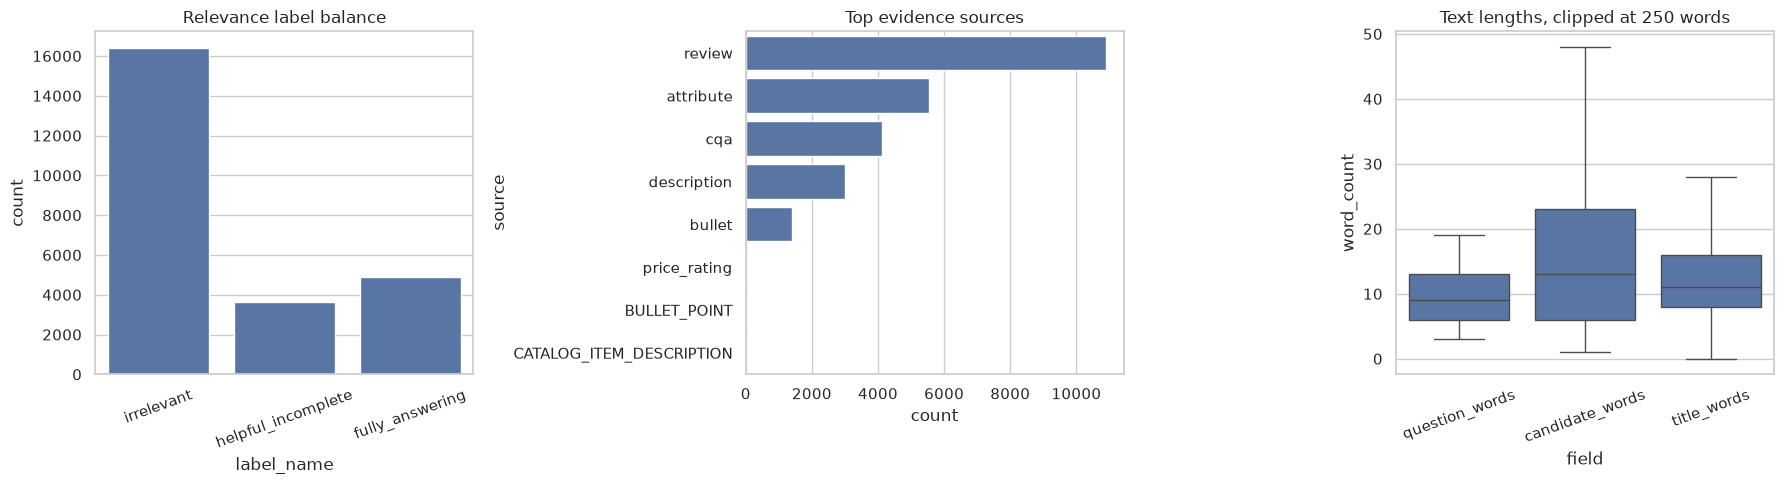

In [13]:
label_names = {0: "irrelevant", 1: "helpful_incomplete", 2: "fully_answering"}
eda_df = curated_df.copy()
eda_df["label_name"] = eda_df["label"].map(label_names)
for column in ["question", "candidate", "title", "answer"]:
    eda_df[f"{column}_words"] = eda_df[column].str.split().str.len()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.countplot(data=eda_df, x="label_name", order=list(label_names.values()), ax=axes[0])
axes[0].set_title("Relevance label balance")
axes[0].tick_params(axis="x", rotation=20)

top_sources = eda_df["source"].value_counts().head(10).index
sns.countplot(
    data=eda_df[eda_df["source"].isin(top_sources)],
    y="source",
    order=top_sources,
    ax=axes[1],
)
axes[1].set_title("Top evidence sources")

length_plot = eda_df[["question_words", "candidate_words", "title_words"]].clip(upper=250).melt(
    var_name="field", value_name="word_count"
)
sns.boxplot(data=length_plot, x="field", y="word_count", showfliers=False, ax=axes[2])
axes[2].set_title("Text lengths, clipped at 250 words")
axes[2].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

In [14]:
candidates_per_question = curated_df.groupby("qid").size()
source_label = pd.crosstab(eda_df["source"], eda_df["label_name"], normalize="index").round(3)
source_order = eda_df["source"].value_counts().index
display(candidates_per_question.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).to_frame("candidates_per_question"))
display(source_label.reindex(source_order).head(15))

pii_patterns = {
    "email_like": r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
    "phone_like": r"(?<!\d)(?:\+?\d[\d .()-]{7,}\d)(?!\d)",
    "card_like": r"(?<!\d)(?:\d[ -]*?){13,19}(?!\d)",
}
combined_text = curated_df[TEXT_COLUMNS].agg(" ".join, axis=1)
pii_scan = {
    name: int(combined_text.str.contains(pattern, case=False, regex=True, na=False).sum())
    for name, pattern in pii_patterns.items()
}
print("Potential sensitive-text matches for manual review (heuristic, may include false positives):")
print(json.dumps(pii_scan, indent=2))


,candidates_per_question
count,2497.000000
mean,9.998398
std,0.147078
min,8.000000
50%,10.000000
90%,10.000000
95%,10.000000
99%,10.000000
max,11.000000


label_name,fully_answering,helpful_incomplete,irrelevant
source,,,
review,0.239,0.170,0.591
attribute,0.069,0.043,0.888
cqa,0.362,0.298,0.339
description,0.086,0.064,0.850
bullet,0.127,0.087,0.786
price_rating,0.000,0.000,1.000
BULLET_POINT,1.000,0.000,0.000
CATALOG_ITEM_DESCRIPTION,0.000,0.000,1.000


Potential sensitive-text matches for manual review (heuristic, may include false positives):
{
  "email_like": 16,
  "phone_like": 884,
  "card_like": 46
}


The following feature set is deliberately tabular and inexpensive. Dense sentence embeddings belong in the retrieval index, while SageMaker Feature Store holds reusable scalar and categorical features. `HashingVectorizer` is stateless, so computing the cosine feature before the split does not fit vocabulary or IDF statistics on validation, test, or production data.


## 5 Feature engineering


In [17]:
feature_source_columns = {"question", "candidate", "title", "answer", "asin", "qid", "qa_pair_id", "source", "source_split", "label"}
missing_feature_columns = sorted(feature_source_columns - set(curated_df.columns))
if missing_feature_columns:
    raise ValueError(f"Feature engineering cannot continue; curated_df is missing: {missing_feature_columns}")

TOKEN_PATTERN = re.compile(r"[a-z0-9]+(?:[.-][a-z0-9]+)*")
NUMBER_PATTERN = re.compile(r"\b\d+(?:\.\d+)?\b")

def tokens(text):
    return TOKEN_PATTERN.findall(str(text).lower())

def question_type(text):
    normalized = str(text).strip().lower()
    if re.search(r"\b(compatible|compatibility|fit|fits|work with|support)\b", normalized):
        return "compatibility"
    if re.search(r"\b(size|dimension|width|height|length|weight|inch|cm|mm|lb)\b", normalized):
        return "dimensions"
    if re.search(r"\b(color|material|made of|specification|spec)\b", normalized):
        return "specification"
    if re.search(r"\b(warranty|guarantee|return)\b", normalized):
        return "warranty"
    if re.match(r"^(is|are|can|does|do|will|has|have|was|were)\b", normalized):
        return "yes_no"
    return "other"

def row_lexical_features(row):
    question_tokens = tokens(row.question)
    candidate_tokens = tokens(row.candidate)
    q_set, c_set = set(question_tokens), set(candidate_tokens)
    intersection = q_set & c_set
    union = q_set | c_set
    q_numbers = set(NUMBER_PATTERN.findall(row.question))
    c_numbers = set(NUMBER_PATTERN.findall(row.candidate))
    return pd.Series({
        "question_word_count": len(question_tokens),
        "candidate_word_count": len(candidate_tokens),
        "title_word_count": len(tokens(row.title)),
        "answer_word_count": len(tokens(row.answer)),
        "token_overlap_count": len(intersection),
        "token_jaccard": len(intersection) / max(len(union), 1),
        "number_overlap_count": len(q_numbers & c_numbers),
        "question_has_number": int(bool(q_numbers)),
        "candidate_has_number": int(bool(c_numbers)),
        "candidate_in_title": int(bool(row.candidate) and row.candidate.lower() in row.title.lower()),
        "missing_title": int(not bool(row.title)),
        "missing_answer": int(not bool(row.answer)),
    })

lexical_features = curated_df.apply(row_lexical_features, axis=1)

hashing_vectorizer = HashingVectorizer(
    n_features=2**14,
    alternate_sign=False,
    norm="l2",
    lowercase=True,
    ngram_range=(1, 2),
)
question_matrix = hashing_vectorizer.transform(curated_df["question"])
candidate_matrix = hashing_vectorizer.transform(curated_df["candidate"])
hash_cosine_similarity = np.asarray(question_matrix.multiply(candidate_matrix).sum(axis=1)).ravel()

features_df = pd.DataFrame({
    "asin": curated_df["asin"].replace("", "UNKNOWN"),
    "qid": curated_df["qid"],
    "qa_pair_id": curated_df["qa_pair_id"].replace("", "UNKNOWN"),
    "source": curated_df["source"].replace("", "unknown"),
    "source_split": curated_df["source_split"],
    "question_type": curated_df["question"].map(question_type),
    "label": curated_df["label"].astype("int64"),
    "question_char_count": curated_df["question"].str.len().astype("int64"),
    "candidate_char_count": curated_df["candidate"].str.len().astype("int64"),
    "title_char_count": curated_df["title"].str.len().astype("int64"),
    "answer_char_count": curated_df["answer"].str.len().astype("int64"),
    "hash_cosine_similarity": hash_cosine_similarity.astype("float64"),
})
features_df = pd.concat([features_df, lexical_features.reset_index(drop=True)], axis=1)

def make_record_id(row):
    # qa_pair_id is not globally unique in ePQA. Candidate text is part of the
    # pair identity, so include it to prevent deterministic ID collisions.
    material = "\x1f".join([
        str(row.source_split), str(row.qid), str(row.qa_pair_id),
        str(row.asin), str(row.candidate),
    ])
    return hashlib.sha256(material.encode("utf-8")).hexdigest()[:40]

record_ids = curated_df[["source_split", "qid", "qa_pair_id", "asin", "candidate"]].apply(
    make_record_id, axis=1
).reset_index(drop=True)
features_df.insert(0, "record_id", record_ids)
features_df.insert(1, "event_time", float(event_time_epoch))

integral_columns = [
    "label", "question_char_count", "candidate_char_count", "title_char_count",
    "answer_char_count", "question_word_count", "candidate_word_count",
    "title_word_count", "answer_word_count", "token_overlap_count",
    "number_overlap_count", "question_has_number", "candidate_has_number",
    "candidate_in_title", "missing_title", "missing_answer",
]
features_df[integral_columns] = features_df[integral_columns].astype("int64")
features_df["token_jaccard"] = features_df["token_jaccard"].astype("float64")
assert features_df["record_id"].is_unique, "Record IDs must be unique after candidate-aware hashing."
assert not features_df.isna().any().any()
display(features_df.head())
display(features_df.describe(include="all").T)


,record_id,event_time,asin,qid,qa_pair_id,source,source_split,question_type,label,question_char_count,candidate_char_count,title_char_count,answer_char_count,hash_cosine_similarity,question_word_count,candidate_word_count,title_word_count,answer_word_count,token_overlap_count,token_jaccard,number_overlap_count,question_has_number,candidate_has_number,candidate_in_title,missing_title,missing_answer
0,f1ed4b795339a45271e2fad7b72a0b7754448b46,1.790321e+09,B00E37TR5U,39,350,review,train,other,1,81,94,134,147,0.139262,13,17,15,29,3,0.115385,0,0,1,0,0,0
1,34778c0fa264d4a2611b09bc370227687ca173a9,1.790321e+09,B00E37TR5U,39,351,review,train,other,1,81,42,134,91,0.055470,13,8,15,19,1,0.050000,0,0,1,0,0,0
2,f3cfa20758b2253dc6a8a9e67aeb1cf17c61cd1b,1.790321e+09,B00E37TR5U,39,352,review,train,other,1,81,83,134,133,0.111417,13,18,15,29,2,0.071429,0,0,1,0,0,0
3,f72c26ff09fe628efa58d40d468814ad2c374747,1.790321e+09,B00E37TR5U,39,353,review,train,other,2,81,82,134,120,0.101419,13,18,15,25,2,0.071429,0,0,1,0,0,0
4,47673684ea50f7f767ca3cdadedd46f2a15796ce,1.790321e+09,B00E37TR5U,39,354,review,train,other,2,81,40,134,76,0.166410,13,9,15,15,3,0.157895,0,0,1,0,0,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
record_id,24966,24966,9e3e3d7629f2748ff6b502bcc83d9060c0ee5f01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_time,24966.0,NaN,NaN,NaN,1790320729.694591,0.0,1790320729.69459,1790320729.69459,1790320729.69459,1790320729.69459,1790320729.69459
asin,24966,2128,B0050KKS5C,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN
qid,24966,2497,3816,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
qa_pair_id,24966,24942,-1,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source,24966,8,review,10885,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source_split,24966,3,train,20027,NaN,NaN,NaN,NaN,NaN,NaN,NaN
question_type,24966,6,yes_no,11095,NaN,NaN,NaN,NaN,NaN,NaN,NaN
label,24966.0,NaN,NaN,NaN,0.539253,0.801387,0.0,0.0,0.0,1.0,2.0
question_char_count,24966.0,NaN,NaN,NaN,50.466635,23.122822,9.0,32.0,46.0,66.0,148.0


In [19]:
features_path = local_dir / "epqa_pair_features.parquet"
features_df.to_parquet(features_path, index=False, compression="snappy")
features_key = f"{base_prefix}/features/epqa_pair_features/data.parquet"
s3.upload_file(str(features_path), bucket, features_key)
feature_object = s3.head_object(Bucket=bucket, Key=features_key)
print(f"Feature Parquet: s3://{bucket}/{features_key}")
print(f"Uploaded bytes: {feature_object['ContentLength']:,}")


Feature Parquet: s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925_071849/features/epqa_pair_features/data.parquet
Uploaded bytes: 1,505,948


## 6 Create a SageMaker Feature Store offline feature group and ingest records


In [21]:
STRING_FEATURES = ["record_id", "asin", "qid", "qa_pair_id", "source", "source_split", "question_type"]
FRACTIONAL_FEATURES = ["event_time", "hash_cosine_similarity", "token_jaccard"]
INTEGRAL_FEATURES = integral_columns

feature_definitions = (
    [{"FeatureName": name, "FeatureType": "String"} for name in STRING_FEATURES]
    + [{"FeatureName": name, "FeatureType": "Fractional"} for name in FRACTIONAL_FEATURES]
    + [{"FeatureName": name, "FeatureType": "Integral"} for name in INTEGRAL_FEATURES]
)

defined_feature_names = {item["FeatureName"] for item in feature_definitions}
if defined_feature_names != set(features_df.columns):
    raise ValueError(
        f"Feature Store schema mismatch. Missing definitions: {sorted(set(features_df.columns) - defined_feature_names)}; "
        f"extra definitions: {sorted(defined_feature_names - set(features_df.columns))}"
    )

feature_group_name = f"aai540-{PROJECT_NAME}-pairs-{run_id.replace('_', '-')}"[:64]
offline_store_uri = f"s3://{bucket}/aai540/{PROJECT_NAME}/feature-store"

try:
    sm.create_feature_group(
        FeatureGroupName=feature_group_name,
        RecordIdentifierFeatureName="record_id",
        EventTimeFeatureName="event_time",
        FeatureDefinitions=feature_definitions,
        OnlineStoreConfig={"EnableOnlineStore": False},
        OfflineStoreConfig={
            "S3StorageConfig": {"S3Uri": offline_store_uri},
            "DisableGlueTableCreation": False,
        },
        RoleArn=execution_role_arn,
        Description="AAI 540 ePQA pair-level scalar ranking features for supervised learning.",
        Tags=[
            {"Key": "project", "Value": PROJECT_NAME},
            {"Key": "course", "Value": "AAI-540"},
            {"Key": "run-id", "Value": run_id},
        ],
    )
    print(f"Creating feature group: {feature_group_name}")
except ClientError as exc:
    error_code = exc.response.get("Error", {}).get("Code", "")
    if error_code == "ResourceInUse":
        print(f"Feature group already exists: {feature_group_name}")
    else:
        raise RuntimeError(
            "Feature group creation failed. Confirm sagemaker:CreateFeatureGroup, iam:PassRole, "
            "Glue, and S3 permissions for the execution role."
        ) from exc

deadline = time.time() + 15 * 60
while True:
    fg_description = sm.describe_feature_group(FeatureGroupName=feature_group_name)
    status = fg_description["FeatureGroupStatus"]
    print(f"Feature group status: {status}", end="\r")
    if status == "Created":
        break
    if status in {"CreateFailed", "DeleteFailed"}:
        raise RuntimeError(f"Feature group entered terminal state {status}: {fg_description}")
    if time.time() >= deadline:
        raise TimeoutError("Feature group was not ready within 15 minutes.")
    time.sleep(15)
print(f"\nFeature group ready: {feature_group_name}")
display(pd.Series({
    "feature_group_arn": fg_description.get("FeatureGroupArn"),
    "offline_s3_uri": fg_description.get("OfflineStoreConfig", {}).get("S3StorageConfig", {}).get("ResolvedOutputS3Uri"),
    "glue_database": fg_description.get("OfflineStoreConfig", {}).get("DataCatalogConfig", {}).get("Database"),
    "glue_table": fg_description.get("OfflineStoreConfig", {}).get("DataCatalogConfig", {}).get("TableName"),
}).to_frame("value"))


Feature group already exists: aai540-product-qa-pairs-20260925-071849
Feature group status: Created
Feature group ready: aai540-product-qa-pairs-20260925-071849


,value
feature_group_arn,arn:aws:sagemaker:us-east-1:070881885726:feature-group/aai540-product-qa-pairs-20260925-071849
offline_s3_uri,s3://sagemaker-us-east-1-070881885726/aai540/product-qa/feature-store/070881885726/sagemaker/us-east-1/offline-store...
glue_database,sagemaker_featurestore
glue_table,aai540_product_qa_pairs_20260925_071849_1790321749


In [22]:
feature_type_by_name = {
    item["FeatureName"]: item["FeatureType"] for item in feature_definitions
}
ordered_feature_names = [item["FeatureName"] for item in feature_definitions]

def value_as_string(value, feature_type):
    if feature_type == "Integral":
        return str(int(value))
    if feature_type == "Fractional":
        return format(float(value), ".12g")
    return str(value)

def put_feature_record(row_values):
    record = [
        {
            "FeatureName": name,
            "ValueAsString": value_as_string(row_values[name], feature_type_by_name[name]),
        }
        for name in ordered_feature_names
    ]
    fs_runtime.put_record(
        FeatureGroupName=feature_group_name,
        Record=record,
        TargetStores=["OfflineStore"],
    )
    return row_values["record_id"]

records = features_df[ordered_feature_names].to_dict(orient="records")
with ThreadPoolExecutor(max_workers=FEATURE_STORE_WORKERS) as executor:
    accepted_record_ids = list(tqdm(
        executor.map(put_feature_record, records),
        total=len(records),
        desc="Feature Store PutRecord",
    ))

assert len(accepted_record_ids) == len(features_df)
print(f"Accepted {len(accepted_record_ids):,} records for the Feature Store offline store.")
print("Offline-store Parquet delivery is asynchronous and can take several minutes.")


Feature Store PutRecord:   0%|          | 0/24966 [00:00<?, ?it/s]

Accepted 24,966 records for the Feature Store offline store.
Offline-store Parquet delivery is asynchronous and can take several minutes.


## 7 Make leakage-safe 40 10 10 40 splits grouped by product


In [23]:
# Use ASIN as the group. Fall back to qid only for records with a missing product identifier.
split_source = features_df.copy()
split_source["split_group"] = np.where(
    split_source["asin"].ne("UNKNOWN"),
    "asin:" + split_source["asin"],
    "qid:" + split_source["qid"],
)
if split_source["split_group"].nunique() < 4:
    raise ValueError("At least four product/question groups are required for four-way splitting.")

# 40% production, then 40/10/10 from the remaining 60%.
remaining_idx, production_idx = next(GroupShuffleSplit(
    n_splits=1, test_size=0.40, random_state=RANDOM_SEED
).split(split_source, groups=split_source["split_group"]))
remaining = split_source.iloc[remaining_idx].copy()
production = split_source.iloc[production_idx].copy()

train_idx, holdout_idx = next(GroupShuffleSplit(
    n_splits=1, test_size=1/3, random_state=RANDOM_SEED + 1
).split(remaining, groups=remaining["split_group"]))
train = remaining.iloc[train_idx].copy()
holdout = remaining.iloc[holdout_idx].copy()

validation_idx, test_idx = next(GroupShuffleSplit(
    n_splits=1, test_size=0.50, random_state=RANDOM_SEED + 2
).split(holdout, groups=holdout["split_group"]))
validation = holdout.iloc[validation_idx].copy()
test = holdout.iloc[test_idx].copy()

splits = {"train": train, "validation": validation, "test": test, "production": production}
for name, frame in splits.items():
    splits[name] = frame.drop(columns="split_group").reset_index(drop=True)

# Product groups must be disjoint across every split.
group_sets = {
    name: set(frame["asin"].where(frame["asin"].ne("UNKNOWN"), frame["qid"]))
    for name, frame in splits.items()
}
for left_name, left_groups in group_sets.items():
    for right_name, right_groups in group_sets.items():
        if left_name < right_name:
            overlap = left_groups & right_groups
            assert not overlap, f"Leakage between {left_name} and {right_name}: {list(overlap)[:5]}"

split_summary = pd.DataFrame([
    {
        "split": name,
        "rows": len(frame),
        "row_pct": len(frame) / len(features_df),
        "unique_products_or_fallback_questions": len(group_sets[name]),
        "label_0_pct": frame["label"].eq(0).mean(),
        "label_1_pct": frame["label"].eq(1).mean(),
        "label_2_pct": frame["label"].eq(2).mean(),
    }
    for name, frame in splits.items()
]).set_index("split")
all_split_record_ids = pd.concat(
    [frame[["record_id"]].assign(split=name) for name, frame in splits.items()],
    ignore_index=True,
)
assert len(all_split_record_ids) == len(features_df), "Split row counts do not add up to the feature dataset."
assert all_split_record_ids["record_id"].is_unique, "A record appears in more than one split."
assert set(all_split_record_ids["record_id"]) == set(features_df["record_id"]), "A record is missing from the splits."

display(split_summary.style.format({
    "row_pct": "{:.1%}", "label_0_pct": "{:.1%}",
    "label_1_pct": "{:.1%}", "label_2_pct": "{:.1%}",
}))


,rows,row_pct,unique_products_or_fallback_questions,label_0_pct,label_1_pct,label_2_pct
split,,,,,,
train,10086,40.4%,850,66.0%,14.2%,19.8%
validation,2469,9.9%,213,65.7%,16.3%,18.0%
test,2465,9.9%,213,65.4%,15.5%,19.2%
production,9946,39.8%,852,65.7%,14.2%,20.1%


In [24]:
split_uris = {}
for split_name, split_df in splits.items():
    local_path = local_dir / f"{split_name}.parquet"
    split_df.to_parquet(local_path, index=False, compression="snappy")
    key = f"{base_prefix}/splits/{split_name}/data.parquet"
    s3.upload_file(str(local_path), bucket, key)
    split_uris[split_name] = f"s3://{bucket}/{key}"

split_manifest = {
    "run_id": run_id,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "seed": RANDOM_SEED,
    "schema_version": "epqa-csv-title-v1",
    "record_id_strategy": "sha256(source_split,qid,qa_pair_id,asin,candidate)[:40]",
    "grouping": "ASIN; qid fallback when ASIN is missing",
    "requested_row_ratios": {"train": 0.40, "validation": 0.10, "test": 0.10, "production": 0.40},
    "actual": {
        name: {
            "rows": int(len(frame)),
            "ratio": float(len(frame) / len(features_df)),
            "s3_uri": split_uris[name],
        }
        for name, frame in splits.items()
    },
}
split_manifest_key = f"{base_prefix}/splits/split_manifest.json"
s3.put_object(
    Bucket=bucket,
    Key=split_manifest_key,
    Body=json.dumps(split_manifest, indent=2).encode("utf-8"),
    ContentType="application/json",
)
for split_name, uri in split_uris.items():
    split_key = uri.replace(f"s3://{bucket}/", "", 1)
    uploaded_bytes = s3.head_object(Bucket=bucket, Key=split_key)["ContentLength"]
    print(f"{split_name}: {uri} ({uploaded_bytes:,} bytes)")
print(json.dumps(split_manifest, indent=2))


train: s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925_071849/splits/train/data.parquet (627,758 bytes)
validation: s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925_071849/splits/validation/data.parquet (170,401 bytes)
test: s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925_071849/splits/test/data.parquet (171,035 bytes)
production: s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925_071849/splits/production/data.parquet (619,092 bytes)
{
  "run_id": "20260925_071849",
  "created_at_utc": "2026-09-25T07:37:22.628562+00:00",
  "seed": 540,
  "schema_version": "epqa-csv-title-v1",
  "record_id_strategy": "sha256(source_split,qid,qa_pair_id,asin,candidate)[:40]",
  "grouping": "ASIN; qid fallback when ASIN is missing",
  "requested_row_ratios": {
    "train": 0.4,
    "validation": 0.1,
    "test": 0.1,
    "production": 0.4
  },
  "actual": {
    "train": {
      "rows": 10086,
      "ratio": 0.4039894256188

## 8 Create AWS Glue Athena tables and run validation queries


In [26]:
database_name = "aai540_product_qa"
table_suffix = run_id.lower()
athena_output = f"s3://{bucket}/aai540/{PROJECT_NAME}/athena-results/"

try:
    glue.create_database(DatabaseInput={
        "Name": database_name,
        "Description": "AAI 540 product question answering data lake",
    })
    print(f"Created Glue database: {database_name}")
except glue.exceptions.AlreadyExistsException:
    print(f"Using existing Glue database: {database_name}")

def run_athena(sql, database=None, timeout_seconds=600):
    request = {
        "QueryString": sql,
        "ResultConfiguration": {"OutputLocation": athena_output},
        "WorkGroup": ATHENA_WORKGROUP,
    }
    if database:
        request["QueryExecutionContext"] = {"Database": database, "Catalog": "AwsDataCatalog"}
    query_id = athena.start_query_execution(**request)["QueryExecutionId"]
    deadline = time.time() + timeout_seconds
    while True:
        execution = athena.get_query_execution(QueryExecutionId=query_id)["QueryExecution"]
        state = execution["Status"]["State"]
        if state == "SUCCEEDED":
            return query_id
        if state in {"FAILED", "CANCELLED"}:
            reason = execution["Status"].get("StateChangeReason", "No reason returned")
            raise RuntimeError(f"Athena query {query_id} {state}: {reason}\n\nSQL:\n{sql}")
        if time.time() >= deadline:
            athena.stop_query_execution(QueryExecutionId=query_id)
            raise TimeoutError(f"Athena query {query_id} exceeded {timeout_seconds} seconds")
        time.sleep(2)

def athena_results_dataframe(query_id):
    paginator = athena.get_paginator("get_query_results")
    rows = []
    for page in paginator.paginate(QueryExecutionId=query_id):
        for row in page["ResultSet"]["Rows"]:
            rows.append([cell.get("VarCharValue") for cell in row.get("Data", [])])
    if not rows:
        return pd.DataFrame()
    header, data = rows[0], rows[1:]
    width = len(header)
    data = [row + [None] * (width - len(row)) for row in data]
    return pd.DataFrame(data, columns=header)

def athena_type(dtype):
    if pd.api.types.is_integer_dtype(dtype):
        return "bigint"
    if pd.api.types.is_float_dtype(dtype):
        return "double"
    if pd.api.types.is_bool_dtype(dtype):
        return "boolean"
    return "string"

def parquet_table_input(table_name, dataframe, s3_location, description):
    return {
        "Name": table_name,
        "Description": description,
        "TableType": "EXTERNAL_TABLE",
        "Parameters": {
            "EXTERNAL": "TRUE",
            "classification": "parquet",
        },
        "StorageDescriptor": {
            "Columns": [
                {"Name": str(column).lower(), "Type": athena_type(dtype)}
                for column, dtype in dataframe.dtypes.items()
            ],
            "Location": s3_location,
            "InputFormat": "org.apache.hadoop.hive.ql.io.parquet.MapredParquetInputFormat",
            "OutputFormat": "org.apache.hadoop.hive.ql.io.parquet.MapredParquetOutputFormat",
            "Compressed": False,
            "NumberOfBuckets": -1,
            "SerdeInfo": {
                "SerializationLibrary": "org.apache.hadoop.hive.ql.io.parquet.serde.ParquetHiveSerDe",
                "Parameters": {"serialization.format": "1"},
            },
            "StoredAsSubDirectories": False,
        },
    }

def upsert_glue_table(table_input):
    table_name = table_input["Name"]
    try:
        glue.create_table(DatabaseName=database_name, TableInput=table_input)
        action = "Created"
    except glue.exceptions.AlreadyExistsException:
        glue.update_table(DatabaseName=database_name, TableInput=table_input)
        action = "Updated"
    registered = glue.get_table(DatabaseName=database_name, Name=table_name)["Table"]
    print(f"{action} {database_name}.{table_name} -> {registered['StorageDescriptor']['Location']}")
    return registered

raw_table = f"epqa_raw_{table_suffix}"
curated_table = f"epqa_curated_{table_suffix}"
features_table = f"epqa_features_{table_suffix}"
split_tables = {name: f"epqa_{name}_{table_suffix}" for name in splits}

raw_table_input = {
    "Name": raw_table,
    "Description": "Immutable ePQA source CSV files",
    "TableType": "EXTERNAL_TABLE",
    "Parameters": {
        "EXTERNAL": "TRUE",
        "classification": "csv",
        "skip.header.line.count": "1",
    },
    "StorageDescriptor": {
        "Columns": [
            {"Name": "qid", "Type": "string"},
            {"Name": "question", "Type": "string"},
            {"Name": "asin", "Type": "string"},
            {"Name": "candidate", "Type": "string"},
            {"Name": "source", "Type": "string"},
            {"Name": "qa_pair_id", "Type": "string"},
            {"Name": "title", "Type": "string"},
            {"Name": "label", "Type": "string"},
            {"Name": "answer", "Type": "string"},
        ],
        "Location": f"s3://{bucket}/{raw_files_prefix}/",
        "InputFormat": "org.apache.hadoop.mapred.TextInputFormat",
        "OutputFormat": "org.apache.hadoop.hive.ql.io.HiveIgnoreKeyTextOutputFormat",
        "Compressed": False,
        "NumberOfBuckets": -1,
        "SerdeInfo": {
            "SerializationLibrary": "org.apache.hadoop.hive.serde2.OpenCSVSerde",
            "Parameters": {
                "separatorChar": ",",
                "quoteChar": "\"",
                "escapeChar": "\\",
            },
        },
        "StoredAsSubDirectories": False,
    },
}

table_inputs = {
    raw_table: raw_table_input,
    curated_table: parquet_table_input(
        curated_table,
        curated_df,
        f"s3://{bucket}/{base_prefix}/curated/epqa/data/",
        "Validated and normalized ePQA records",
    ),
    features_table: parquet_table_input(
        features_table,
        features_df,
        f"s3://{bucket}/{base_prefix}/features/epqa_pair_features/",
        "Engineered ePQA pair-level scalar features",
    ),
}
for split_name, split_df in splits.items():
    table_name = split_tables[split_name]
    table_inputs[table_name] = parquet_table_input(
        table_name,
        split_df,
        f"s3://{bucket}/{base_prefix}/splits/{split_name}/",
        f"ePQA {split_name} feature split",
    )

registered_tables = {
    table_name: upsert_glue_table(table_input)
    for table_name, table_input in table_inputs.items()
}
assert set(registered_tables) == set(table_inputs)
print(f"Registered {len(registered_tables)} Glue tables for Athena without SQL DDL.")


Using existing Glue database: aai540_product_qa
Created aai540_product_qa.epqa_raw_20260925_071849 -> s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925_071849/raw/epqa/files/
Created aai540_product_qa.epqa_curated_20260925_071849 -> s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925_071849/curated/epqa/data/
Created aai540_product_qa.epqa_features_20260925_071849 -> s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925_071849/features/epqa_pair_features/
Created aai540_product_qa.epqa_train_20260925_071849 -> s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925_071849/splits/train/
Created aai540_product_qa.epqa_validation_20260925_071849 -> s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925_071849/splits/validation/
Created aai540_product_qa.epqa_test_20260925_071849 -> s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925_071849/splits/test/
Created aai540_product_qa.epqa_produc

In [27]:
split_union = "\nUNION ALL\n".join(
    f"SELECT '{name}' AS split_name, count(*) AS rows, "
    f"count(DISTINCT asin) AS products, avg(CAST(label AS double)) AS mean_label "
    f"FROM \"{database_name}\".\"{table_name}\""
    for name, table_name in split_tables.items()
)
split_query_id = run_athena(
    f"SELECT * FROM ({split_union}) ORDER BY split_name",
    database=database_name,
)
display(athena_results_dataframe(split_query_id))

distribution_query_id = run_athena(
    f"""
    SELECT source, label, count(*) AS records
    FROM "{database_name}"."{features_table}"
    GROUP BY source, label
    ORDER BY records DESC
    LIMIT 25
    """,
    database=database_name,
)
display(athena_results_dataframe(distribution_query_id))


,split_name,rows,products,mean_label
0,production,9946,852,0.5445405188015282
1,test,2465,213,0.5383367139959432
2,train,10086,850,0.5382708705135831
3,validation,2469,213,0.5228837586067233


,source,label,records
0,review,0,6438
1,attribute,0,4931
2,review,2,2598
3,description,0,2542
4,review,1,1849
5,cqa,2,1496
6,cqa,0,1400
7,cqa,1,1232
8,bullet,0,1105
9,attribute,2,385


### Optional Feature Store offline-table check

Feature Store creates its own Glue table. Offline records are delivered asynchronously, often several minutes after `PutRecord` returns. The next cell discovers that table and queries it. If the result is zero immediately after ingestion, wait a few minutes and rerun only this cell.


In [28]:
fg_description = sm.describe_feature_group(FeatureGroupName=feature_group_name)
catalog_config = fg_description["OfflineStoreConfig"]["DataCatalogConfig"]
feature_store_database = catalog_config["Database"]
feature_store_table = catalog_config["TableName"]
print(f"Feature Store catalog table: {feature_store_database}.{feature_store_table}")

try:
    fs_count_query_id = run_athena(
        f'SELECT count(*) AS offline_records FROM "{feature_store_database}"."{feature_store_table}"',
        database=feature_store_database,
    )
    display(athena_results_dataframe(fs_count_query_id))
except RuntimeError as exc:
    print("The Feature Store Glue table or its newest files are not queryable yet.")
    print("Wait 5-10 minutes and rerun this cell. Details:", exc)


Feature Store catalog table: sagemaker_featurestore.aai540_product_qa_pairs_20260925_071849_1790321749


,offline_records
0,24966


## 9 Final run summary


In [29]:
# Re-read Feature Store catalog metadata so this summary does not depend on the optional check cell.
fg_description = sm.describe_feature_group(FeatureGroupName=feature_group_name)
catalog_config = fg_description["OfflineStoreConfig"]["DataCatalogConfig"]
feature_store_database = catalog_config["Database"]
feature_store_table = catalog_config["TableName"]

artifacts = {
    "run_id": run_id,
    "schema_version": "epqa-csv-title-v1",
    "record_id_strategy": "sha256(source_split,qid,qa_pair_id,asin,candidate)[:40]",
    "region": region,
    "raw_data": f"s3://{bucket}/{base_prefix}/raw/epqa/",
    "curated_data": f"s3://{bucket}/{base_prefix}/curated/epqa/",
    "features_parquet": f"s3://{bucket}/{base_prefix}/features/epqa_pair_features/",
    "split_data": {name: uri for name, uri in split_uris.items()},
    "split_manifest": f"s3://{bucket}/{split_manifest_key}",
    "athena_database": database_name,
    "athena_tables": [raw_table, curated_table, features_table, *split_tables.values()],
    "athena_results": athena_output,
    "feature_group_name": feature_group_name,
    "feature_group_arn": fg_description.get("FeatureGroupArn"),
    "feature_store_glue_database": feature_store_database,
    "feature_store_glue_table": feature_store_table,
}
summary_key = f"{base_prefix}/run_summary.json"
s3.put_object(
    Bucket=bucket,
    Key=summary_key,
    Body=json.dumps(artifacts, indent=2).encode("utf-8"),
    ContentType="application/json",
)
print(json.dumps(artifacts, indent=2))
print(f"\nRun summary saved to s3://{bucket}/{summary_key}")


{
  "run_id": "20260925_071849",
  "schema_version": "epqa-csv-title-v1",
  "record_id_strategy": "sha256(source_split,qid,qa_pair_id,asin,candidate)[:40]",
  "region": "us-east-1",
  "raw_data": "s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925_071849/raw/epqa/",
  "curated_data": "s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925_071849/curated/epqa/",
  "features_parquet": "s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925_071849/features/epqa_pair_features/",
  "split_data": {
    "train": "s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925_071849/splits/train/data.parquet",
    "validation": "s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925_071849/splits/validation/data.parquet",
    "test": "s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925_071849/splits/test/data.parquet",
    "production": "s3://sagemaker-us-east-1-070881885726/aai540/product-qa/runs/20260925

## Cost control and optional cleanup

This notebook does not delete evidence or resources automatically. Keep the S3 run if it is an assignment artifact. SageMaker Feature Store's offline store uses S3 and Glue; this notebook deliberately disables the online store. When you no longer need the feature group, set `DELETE_FEATURE_GROUP = True` below and run the cell. Deleting the feature group does **not** delete its S3 offline files.


In [ ]:
DELETE_FEATURE_GROUP = False

if DELETE_FEATURE_GROUP:
    sm.delete_feature_group(FeatureGroupName=feature_group_name)
    print(f"Delete requested for feature group: {feature_group_name}")
else:
    print("No resources deleted. Set DELETE_FEATURE_GROUP = True only when cleanup is intended.")
